In [1]:
import sys, os
print(sys.executable)

/Users/andresho/Desktop/C-MARL/venv/bin/python3.11


In [2]:
import numpy as np
import time
from dataclasses import dataclass
import tensorflow as tf

In [3]:
sys.path.insert(0, os.path.abspath("../.."))   # sandboxes/test2 -> project root
from game_environments.ToyGame import ToyGame

from core.agents import build_agents
from core.rollout import run_episodes, take_belief_step
from algorithms.gda_baseline import train
# Factored (N-sigmoid, amortized-hidden) belief -- this project's own variant,
# meant to generalize to k>1 adversaries. For the faithful EIR-MAPPO
# reproduction (N+1-way categorical belief), swap this import for
# `from beliefs import categorical_eirmappo as belief_module`, or just run
# experiments/run_baseline.py directly.
from beliefs import factored_sigmoid as belief_module

tf.random.set_seed(0)
np.random.seed(0)

cfg = ToyGame(128)
agents = build_agents(cfg, belief_module, hidden=128)
belief_step = take_belief_step(agents, belief_module)
print("TF", tf.__version__, "| Config:", cfg)


TF 2.14.0 | Config: <game_environments.ToyGame.ToyGame object at 0x13f821d90>


In [ ]:
hist = train(
    ToyGame, agents, belief_step, belief_module,
    B=200, n_iters=100, log_every=100,
    team_interval=10
)


In [ ]:
record = run_episodes(ToyGame(1000), agents, belief_step)


In [7]:
print(record['reward'].shape)
total_reward = np.sum(record['reward'], axis=1)
avg_reward = np.mean(total_reward)
avg_reward2 = np.mean(record['reward'])
print(avg_reward)
print(avg_reward2)

(1000, 100)
99.14
0.9914


In [8]:
print(hist.keys())

dict_keys(['reward_adv', 'reward_clean', 'belief_acc'])


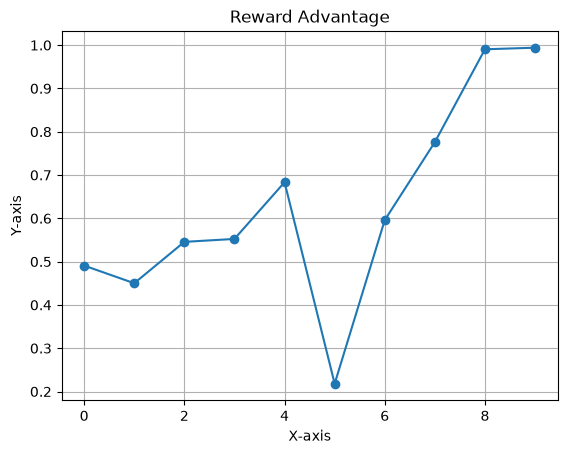

In [9]:
import matplotlib.pyplot as plt
plt.plot(range(len(hist['reward_adv'])),hist['reward_adv'], marker='o')

# Labels and title
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Reward Advantage")

# Optional: grid
plt.grid(True)

# Show plot
plt.show()

In [ ]:
from evaluation.honest_eval import evaluate_robustness
w_before = agents.policy.get_weights()[0].copy()
eval_hist = evaluate_robustness(cfg, agents, belief_step, n_iters=2000, log_every=100)
w_after = agents.policy.get_weights()[0]
print("policy frozen:", np.allclose(w_before, w_after))


In [11]:
eval_hist.keys()

dict_keys(['curve', 'robust_reward_mean', 'robust_reward_min', 'clean_reward'])

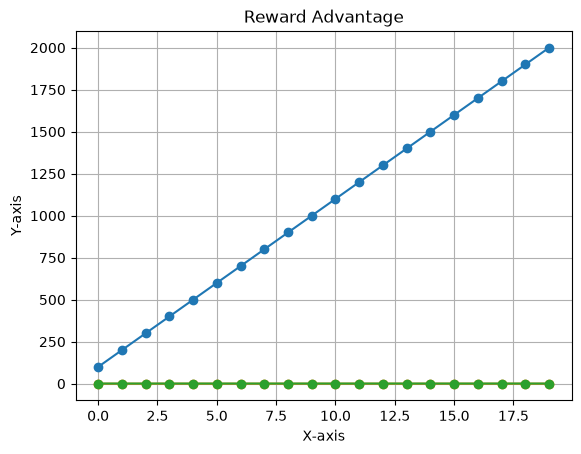

In [12]:
plt.plot(range(len(eval_hist['curve'])),eval_hist['curve'], marker='o')

# Labels and title
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Reward Advantage")

# Optional: grid
plt.grid(True)

# Show plot
plt.show()

In [ ]:
# and: what does the trained team get on clean episodes, right now?
ev = run_episodes(cfg, agents, belief_step)
ep_r = ev['reward'].mean(axis=1)
clean = ep_r[ev['theta'][:,0,:].sum(axis=1)==0].mean()
print("clean reward with trained agents:", clean)   # should be ~0.99
